# Algorithm 3 sandbox

Algorithm 3 of `main.tex` (Section 4.3, the sharp bound), with Algorithm 2 and its variations for comparison, on a toy example. Here $\nu$ is uniform on two circles of radii $1/2$ and $1$, with weight $1/2$ each, in the first $k = 2$ coordinates of $\mathbb R^{10}$, so that $R = 1$; the denoiser $D(x, t) = \mathbb E[X_0 \mid X_t = x]$ and its Jacobian are exact, in closed form. The forward process is that of Proposition 4.8 with $\alpha = 1/2$ and $\beta_t = 10$, down to $\epsilon = 10^{-4}$.

Each step maps the current point $y$ at noise level $s$ to $y'$ at noise level $t < s$, drawn exactly from $q_{1-t|1-s}(\cdot|y)$. The notation is that of `main.tex`: $c_t = \psi_{t,0}/\sigma^2_{t,0}$, $\kappa_{s,t} = \psi^2_{t,0}/\sigma^2_{t,0} - \psi^2_{s,0}/\sigma^2_{s,0}$ (`snr` below is $\psi^2_{r,0}/\sigma^2_{r,0}$), $\bar y_0 = (c_s/c_t)\, y$, $\phi_r$ of (17), $B^{(1)}$ of (22), $\Sigma_0$ and $\Delta(y, y')$, $\hat B_r$ of Lemma 4.9 and $\zeta$ of (26). In the code, `V` is $c_t y' - c_s y$ and `M` is $D(\bar y_0, t)$. Equation numbers are those of `main.pdf` on 2026-11-24.

Every evaluation of $D$ counts as one call, and the Jacobian, where used, is counted with the call at $\bar y_0$; counting it as $d$ calls adds $(d - 1)K$ over $K$ steps. Every step asserts its bound at each point where it evaluates $\phi_r$.

## The example

In [1]:
import time
import numpy as np
from scipy import special, stats
import matplotlib.pyplot as plt

# Forward process f_t = -alpha beta_t, g_t = beta_t^{1/2} with alpha = 1/2 and beta_t = 10 (as in Prop 4.8), down to noise level eps.
ALPHA, BETA, EPS = 0.5, 10.0, 1e-4


class Level:
    """Noise level r: psi_{r,0}, sigma^2_{r,0}, c_r = psi_{r,0} / sigma^2_{r,0} and snr = psi^2_{r,0} / sigma^2_{r,0}."""
    def __init__(self, r):
        self.r, self.psi, self.s2 = r, np.exp(-ALPHA * BETA * r), -np.expm1(-2 * ALPHA * BETA * r) / (2 * ALPHA)
        self.c, self.snr = self.psi / self.s2, self.psi ** 2 / self.s2


def level_from_snr(snr):
    return Level(np.log1p(2 * ALPHA / snr) / (2 * ALPHA * BETA))


KAPPA_TOT = Level(EPS).snr - Level(1.0).snr          # kappa_{1, eps}

# nu: uniform on two circles of radii 1/2 and 1 (weight 1/2 each) in the first k coordinates of R^d.
d, k = 10, 2
RADII, WEIGHTS = np.array([0.5, 1.0]), np.array([0.5, 0.5])
R = RADII.max()


def bessel_ratio(a):
    """E<e, u> for u ~ von Mises-Fisher on S^{k-1} with concentration a."""
    a = np.maximum(a, 1e-12)
    return special.ive(k / 2, a) / special.ive(k / 2 - 1, a)


def log_mgf(a, p):
    """log E exp(a <e, u>) for u uniform on S^{p-1}."""
    x = np.maximum(a, 1e-3)
    exact = special.gammaln(p / 2) + (1 - p / 2) * np.log(x / 2) + np.log(special.ive(p / 2 - 1, x)) + x
    return np.where(a < 1e-3, a ** 2 / (2 * p), exact)


def posterior(X, lev):
    """Law of X_0 given X_r = x: circle weights and von Mises-Fisher concentrations, shape (n, circles)."""
    a = lev.c * np.linalg.norm(X[:, :k], axis=1, keepdims=True) * RADII
    logw = np.log(WEIGHTS) - 0.5 * lev.snr * RADII ** 2 + log_mgf(a, k)
    w = np.exp(logw - logw.max(1, keepdims=True))
    return w / w.sum(1, keepdims=True), a


def D(X, lev):
    """Exact denoiser D(x, r) = E[X_0 | X_r = x], one row per point."""
    w, a = posterior(X, lev)
    out = np.zeros_like(X)
    out[:, :k] = (w * RADII * bessel_ratio(a)).sum(1, keepdims=True) * X[:, :k] / np.linalg.norm(X[:, :k], axis=1, keepdims=True)
    return out


def Sigma(X, lev):
    """Cov[X_0 | X_r = x] = c_r^{-1} grad D(x, r), shape (n, d, d); Sigma_0 is Sigma(ybar_0, t)."""
    w, a = posterior(X, lev)
    A, am = bessel_ratio(a), np.maximum(a, 1e-12)
    e = X[:, :k] / np.linalg.norm(X[:, :k], axis=1, keepdims=True)
    c1 = (w * RADII ** 2 * A / am).sum(1)
    c2 = (w * RADII ** 2 * (1 - k * A / am)).sum(1)
    m = (w * RADII * A).sum(1)[:, None] * e
    S = np.zeros((len(X), d, d))
    S[:, :k, :k] = c1[:, None, None] * np.eye(k) + c2[:, None, None] * e[:, :, None] * e[:, None, :] - m[:, :, None] * m[:, None, :]
    return S


def sample_level(n, lev, rng):
    """n exact draws of X_r."""
    u = rng.standard_normal((n, k))
    x0 = np.zeros((n, d))
    x0[:, :k] = rng.choice(RADII, size=n, p=WEIGHTS)[:, None] * u / np.linalg.norm(u, axis=1, keepdims=True)
    return lev.psi * x0 + np.sqrt(lev.s2) * rng.standard_normal((n, d))


def exact_step(y, S, T, n, rng):
    """n exact draws from q_{1-t|1-s}(.|y), for a single point y: c_t y' = c_s y + kappa_{s,t} X_0 + kappa_{s,t}^{1/2} xi,
    with X_0 drawn from its law given X_s = y."""
    w, a = posterior(y[None], S)
    j = rng.choice(len(RADII), size=n, p=w[0])
    e = y[:k] / np.linalg.norm(y[:k])
    X0 = np.zeros((n, d))
    for i in range(len(RADII)):
        m = np.flatnonzero(j == i)
        if m.size:
            X0[m, :k] = RADII[i] * stats.vonmises_fisher(e, max(a[0, i], 1e-12)).rvs(m.size, random_state=rng)
    kap = T.snr - S.snr
    return (S.c * y + kap * X0 + np.sqrt(kap) * rng.standard_normal((n, d))) / T.c


def phi(Y0, M, V, r, T):
    """phi_r(y, y') of (17), one row per proposal: Y0 = ybar_0, M = D(ybar_0, t), V = c_t y' - c_s y."""
    return -((D(Y0 + r[:, None] * V / T.c, T) - M) * V).sum(1)

## Algorithm 3

The pieces: the length of $z$ in the second term of the proposal, drawn as in Algorithm 1 with $d$ replaced by $d + 2$; its direction, with density proportional to $\langle \Sigma_0 \theta, \theta\rangle$; $\mathbb E[|\xi|^2 e^{\lambda|\xi|}]$ for $\zeta$; $\hat B_r$ and its integral (Lemma 4.9); and the Poisson thinning, in which points below $-\hat B_r$ need no call and the others are examined in the order drawn, one call each, until the first rejection.

In [2]:
def radial(n, dim, lam, rng):
    """|z| with density proportional to x^{dim-1} e^{-x^2/2 + lam x}, as in Algorithm 1 (rejection with a tuned variance,
    (14)-(15)) with d replaced by dim."""
    rho = 0.5 * (lam + np.sqrt(lam ** 2 + 4 * (dim - 1)))                      # (14)
    x, todo = np.empty(n), np.arange(n)
    while todo.size:
        z = rho / np.sqrt(dim - 1) * np.sqrt(rng.chisquare(dim, todo.size))
        ok = rng.random(todo.size) < np.exp(-lam / (2 * rho) * (z - rho) ** 2)    # (15)
        x[todo[ok]] = z[ok]
        todo = todo[~ok]
    return x


def sphere(n, rng):
    u = rng.standard_normal((n, d))
    return u / np.linalg.norm(u, axis=1, keepdims=True)


def direction(ev, U, rng):
    """theta on the unit sphere with density proportional to <Sigma_0 theta, theta>, Sigma_0 = U diag(ev) U': an eigenvector e
    chosen with probability proportional to its eigenvalue, then the direction of a standard Gaussian vector whose
    coordinate along e is replaced by a chi_3 variable with a random sign."""
    n = len(ev)
    i = np.minimum((rng.random(n)[:, None] > np.cumsum(ev / ev.sum(1, keepdims=True), 1)).sum(1), d - 1)
    x = rng.standard_normal((n, d))
    x[np.arange(n), i] = np.sqrt(rng.chisquare(3, n)) * rng.choice([-1, 1], n)
    return np.einsum('nij,nj->ni', U, x / np.linalg.norm(x, axis=1, keepdims=True))


def E_xi2(lam):
    """E[|xi|^2 e^{lam |xi|}] for xi ~ N(0, I) in R^d (Kummer functions), as in (26)."""
    a, lg = (d + 2) / 2, special.gammaln
    return (np.exp(np.log(2) + lg(a) - lg(d / 2)) * special.hyp1f1(a, 0.5, lam ** 2 / 2)
            + lam * np.exp(1.5 * np.log(2) + lg(a + 0.5) - lg(d / 2)) * special.hyp1f1(a + 0.5, 1.5, lam ** 2 / 2))


def Bhat(r, B1, Delta):
    """hat B_r of Lemma 4.9, (23)."""
    B1 = np.maximum(B1, 1e-300)
    e = Delta / B1
    return Delta * -np.expm1(-r * (B1 + e)) / (e + B1 * np.exp(-r * (B1 + e)))


def int_Bhat(B1, Delta):
    """int_0^1 hat B_r dr = log((Delta e^{B1} + B1^2 e^{-Delta/B1}) / (Delta + B1^2)), (24)."""
    B1 = np.maximum(B1, 1e-300)
    p = Delta / (Delta + B1 ** 2)
    with np.errstate(divide='ignore', over='ignore'):
        small = np.log1p(p * np.expm1(np.minimum(B1, 30)) + (1 - p) * np.expm1(-Delta / B1))
        return np.where(B1 < 30, small, np.logaddexp(np.log(p) + B1, np.log1p(-p) - Delta / B1))


def thin(Y0, M, V, T, B1, Delta, go, rng):
    """Poisson thinning of Algorithm 3, for the rows with go: Poisson(hat B_1) points (r, b), uniform on [0, 1] x [-hat B_1, 0].
    Points with b < -hat B_r need no call; the others are examined in the order drawn, one call each, and the proposal is
    rejected at the first with b <= phi_r. Returns (accepted, calls)."""
    top = Bhat(1.0, B1, Delta)
    i = np.repeat(np.arange(len(top)), rng.poisson(top * go))
    r, b = rng.random(i.size), -top[i] * rng.random(i.size)
    above = b >= -Bhat(r, B1[i], Delta[i])
    i, r, b = i[above], r[above], b[above]
    first, cnt = np.full(len(top), np.inf), np.bincount(i, minlength=len(top))
    if i.size:
        p = phi(Y0[i], M[i], V[i], r, T)                     # sandbox: phi at every such point, counted up to the first rejection
        assert np.all(p >= -Bhat(r, B1[i], Delta[i]) * (1 + 1e-7) - 1e-9), 'Lemma 4.9 violated'
        rej = b <= p
        pos = np.arange(i.size) - np.searchsorted(i, i)      # position in drawing order within its row
        np.minimum.at(first, i[rej], pos[rej])
    rej = np.isfinite(first)
    return go & ~rej, np.where(rej, first + 1, cnt)

The step:

- One call: $D(\bar y_0, t)$ and, with `jac=True`, its Jacobian, giving $\Sigma_0 = c_t^{-1} \nabla D(\bar y_0, t)$; with `jac=False`, $\Sigma_0 = (R^2 - |D(\bar y_0, t)|^2)\, I$.
- Line 3: with probability $1/(1 + \zeta)$, the refined proposal (16); otherwise $c_t y' = c_s y + \kappa_{s,t}^{1/2} z$, with $|z|$ and $z/|z|$ drawn as above.
- Line 4: accept with probability $\exp\{\int_0^1 \hat B_r \,\mathrm dr\} / (1 + \frac12 \Delta(y, y')\, e^{B^{(1)}(y, y')})$, without a call; then Poisson thinning under $\hat B_r$.

The log records, for each step, the calls ($1$ for $D(\bar y_0, t)$, plus one per point examined), the proposals, the mean of $\int_0^1 \hat B_r \,\mathrm dr$ over proposals passing line 4, and $-\phi_1 / \hat B_1$ for up to $50$ of them per round, which is not counted.

In [3]:
def prepare(Y, S, T, jac):
    """The one call of the step: D(ybar_0, t) and, if jac, Sigma_0 = c_t^{-1} grad D(ybar_0, t); otherwise
    Sigma_0 = (R^2 - |D(ybar_0, t)|^2) I. Returns ybar_0, D(ybar_0, t), Sigma_0 (eigenvalues, eigenvectors) and log zeta of (26)."""
    kap = T.snr - S.snr
    Y0 = (S.c / T.c) * Y                                      # ybar_0
    M = D(Y0, T)
    MM = (M ** 2).sum(1)
    if jac:
        ev, U = np.linalg.eigh(Sigma(Y0, T))
        ev = np.maximum(ev, 1e-300)
    else:
        ev, U = np.maximum(R ** 2 - MM, 1e-300)[:, None] * np.ones(d), np.broadcast_to(np.eye(d), (len(Y), d, d))
    log_zeta = np.log(kap * ev.sum(1) / (2 * d)) - kap * MM / 2 + np.log(E_xi2(R * np.sqrt(kap)))      # (26)
    return Y0, M, ev, U, log_zeta


def propose(M, ev, U, log_zeta, kap, jac, rng):
    """Line 3 of Algorithm 3, one proposal per row; returns V = c_t y' - c_s y."""
    n = len(M)
    V = kap * M + np.sqrt(kap) * rng.standard_normal((n, d))                    # (16)
    two = np.flatnonzero(rng.random(n) < special.expit(log_zeta))             # the second term, with probability zeta / (1 + zeta)
    if two.size:
        theta = direction(ev[two], U[two], rng) if jac else sphere(two.size, rng)
        V[two] = np.sqrt(kap) * radial(two.size, d + 2, R * np.sqrt(kap), rng)[:, None] * theta   # kappa^{1/2} z
    return V


def B1_Delta(M, ev, U, V):
    """B^{(1)}(y, y') of (22) and Delta(y, y') = <Sigma_0 V, V>, V = c_t y' - c_s y."""
    B1 = np.maximum(R * np.linalg.norm(V, axis=1) - (M * V).sum(1), 0)
    Delta = (np.einsum('nji,nj->ni', U, V) ** 2 * ev).sum(1)
    return B1, Delta


def alg3_step(Y, S, T, rng, jac=True):
    """Algorithm 3 for every row of Y, from noise level S to T."""
    n, kap = len(Y), T.snr - S.snr
    Y0, M, ev, U, log_zeta = prepare(Y, S, T, jac)                            # one call
    Vout, calls, props = np.empty_like(Y), np.ones(n), np.zeros(n)
    area, ratio, todo = [], [], np.arange(n)
    while todo.size:
        t = todo
        props[t] += 1
        V = propose(M[t], ev[t], U[t], log_zeta[t], kap, jac, rng)
        B1, Delta = B1_Delta(M[t], ev[t], U[t], V)
        H = int_Bhat(B1, Delta)
        with np.errstate(divide='ignore', over='ignore'):
            go = np.log(rng.random(t.size)) < H - np.logaddexp(0, np.log(Delta / 2) + B1)     # line 4, no call
        ok, cl = thin(Y0[t], M[t], V, T, B1, Delta, go, rng)
        calls[t] += cl
        g = np.flatnonzero(go)[:50]                                            # diagnostics (not counted)
        area.append(H[go])
        ratio.append(-phi(Y0[t[g]], M[t[g]], V[g], np.ones(g.size), T) / Bhat(1.0, B1[g], Delta[g]))
        Vout[t[ok]] = V[ok]
        todo = t[~ok]
    return Y0 + Vout / T.c, dict(calls=calls, props=props, area=np.concatenate(area).mean(), ratio=np.concatenate(ratio))

## The bound of Lemma 4.9

For one $y$ drawn from the law of $X_s$ and four proposals from line 3: $-\phi_r$ (solid), $\hat B_r$ with $\Sigma_0$ from the Jacobian (dashed) and with $(R^2 - |D(\bar y_0, t)|^2)\, I$ (dotted), and $B^{(1)}$ (thin). The evaluations of $\phi_r$ are not counted.

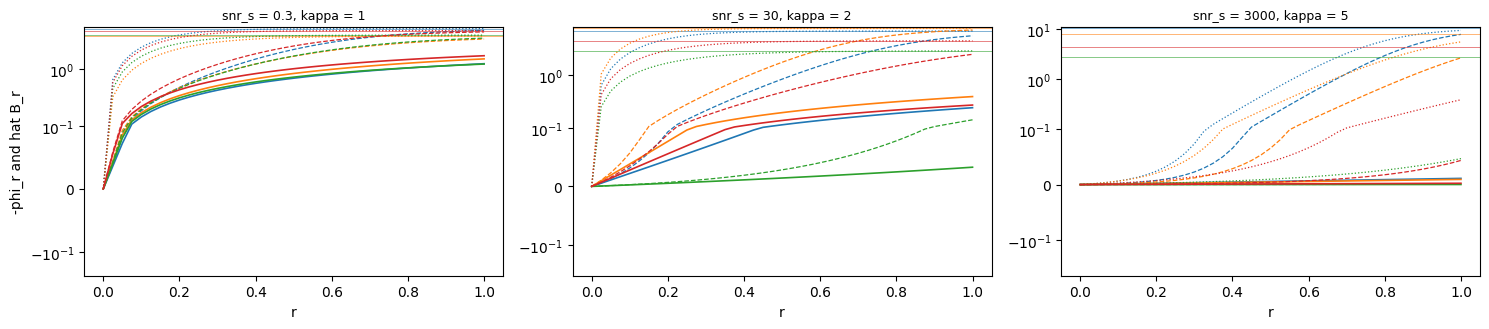

In [4]:
SETTINGS = [(0.3, 1.0), (30, 2.0), (3000, 5.0)]          # (snr_s, kappa_{s,t})
rs = np.linspace(0, 1, 41)
rng = np.random.default_rng(3)

fig, ax = plt.subplots(1, len(SETTINGS), figsize=(5 * len(SETTINGS), 3.4))
for a, (snr_s, kap) in zip(ax, SETTINGS):
    S, T = level_from_snr(snr_s), level_from_snr(snr_s + kap)
    Y = np.repeat(sample_level(1, S, rng), 4, axis=0)
    Y0, M, ev, U, log_zeta = prepare(Y, S, T, jac=True)
    _, _, ev_b, U_b, _ = prepare(Y, S, T, jac=False)
    V = propose(M, ev, U, log_zeta, kap, True, rng)
    B1, Delta = B1_Delta(M, ev, U, V)
    _, Delta_b = B1_Delta(M, ev_b, U_b, V)
    for j in range(len(V)):
        f = -phi(np.repeat(Y0[j:j + 1], rs.size, 0), np.repeat(M[j:j + 1], rs.size, 0), np.repeat(V[j:j + 1], rs.size, 0), rs, T)
        l, = a.plot(rs, f, lw=1.2)
        a.plot(rs, Bhat(rs, B1[j], Delta[j]), '--', c=l.get_color(), lw=0.9)
        a.plot(rs, Bhat(rs, B1[j], Delta_b[j]), ':', c=l.get_color(), lw=0.9)
        a.axhline(B1[j], c=l.get_color(), lw=0.4)
    a.set_title(f'snr_s = {snr_s:g}, kappa = {kap:g}', fontsize=9); a.set_xlabel('r'); a.set_yscale('symlog', linthresh=0.1)
ax[0].set_ylabel('-phi_r and hat B_r')
plt.tight_layout(); plt.show()

## Algorithm 2 and its variations

As in `alg2_sandbox.ipynb`, all with the refined proposal (16) and $\phi_r$ of (17), and with the same log as Algorithm 3.

- `alg2_step`: Algorithm 2 (Section 4.1). Proposal (19), Poisson thinning under $r B^{(2)}$; needs $R^2 \kappa_{s,t} < 1$.
- `capped_step`: Algorithm 5 (Section 4.6). Thinning under $\tilde B_r = \min\{r B^{(2)}, 2R|c_t y' - c_s y|\}$ of (30); the proposal, tilted by the Huber function $\int_0^1 \tilde B_r \,\mathrm dr$, is drawn as a length, by rejection, and a von Mises–Fisher direction. Any $\kappa_{s,t}$.
- `refined_step`: Algorithm 6 (Section 4.7). Thinning under $r B^{(3)}$ of (31), with the Jacobian; the proposal is drawn by rejection from the envelope (32), with $\gamma$ chosen for each $y$ from a grid. Needs $R^2 \kappa_{s,t} < 1$.
- `combo_step` (not in `main.tex`): Algorithm 6 with $r B^{(3)}$ capped at $2R|c_t y' - c_s y|$ as in Section 4.6, so that any $\kappa_{s,t}$ may be taken; the second term of (32) is replaced by the tilt of Section 4.6 restricted to $|c_t y' - c_s y| > \gamma$.
- `combo_step(one_sided=True)` (not in `main.tex`): as `combo_step`, with $B^{(3)}$ further capped by $\Delta(y, y')\,(e^{B^{(1)}} - 1)/B^{(1)}$. This uses only $\langle X_0, c_t y' - c_s y\rangle \leq R|c_t y' - c_s y|$ in the proof of Lemma 4.12, as Lemma 4.9 does.

Left out: Algorithm 1, and the variant of Algorithm 2 with $R^2$ replaced by the largest $-\phi_1/B^{(2)}$ observed, which is not exact.

In [5]:
def alg2_step(Y, S, T, rng):
    """Algorithm 2 for every row of Y: proposal (19), Poisson thinning under r B^{(2)}, B^{(2)} = R^2 |c_t y' - c_s y|^2."""
    n, kap = len(Y), T.snr - S.snr
    a = 1 - R ** 2 * kap
    assert a > 0, 'R^2 kappa >= 1'
    Y0 = (S.c / T.c) * Y
    M = D(Y0, T)                                                  # one call
    Vout, calls, props = np.empty_like(Y), np.ones(n), np.zeros(n)
    area, ratio, todo = [], [], np.arange(n)
    while todo.size:
        t = todo
        props[t] += 1
        V = (kap / a) * M[t] + np.sqrt(kap / a) * rng.standard_normal((t.size, d))     # (19)
        B2 = R ** 2 * (V ** 2).sum(1)
        N = rng.poisson(B2)
        ok = np.ones(t.size, bool)
        for j in range(N.max(initial=0)):                         # j-th Poisson point of every proposal that has one
            i = np.flatnonzero(ok & (N > j))
            r, b = rng.random(i.size), -B2[i] * rng.random(i.size)
            ins = b >= -r * B2[i]                                 # points below -r B^{(2)} need no call
            i, r, b = i[ins], r[ins], b[ins]
            p = phi(Y0[t[i]], M[t[i]], V[i], r, T)
            calls[t[i]] += 1
            assert np.all((p >= -r * B2[i] - 1e-9) & (p <= 1e-9)), 'Lemma 4.6 violated'
            ok[i] = b > p
        h = np.arange(min(50, t.size))                            # diagnostics (not counted)
        area.append(B2 / 2)
        ratio.append(-phi(Y0[t[h]], M[t[h]], V[h], np.ones(h.size), T) / B2[h])
        Vout[t[ok]] = V[ok]
        todo = t[~ok]
    return Y0 + Vout / T.c, dict(calls=calls, props=props, area=np.concatenate(area).mean(), ratio=np.concatenate(ratio))


def huber(rho):
    """int_0^1 tilde B_r dr of Section 4.6, as a function of rho = |c_t y' - c_s y| (a Huber function)."""
    return np.where(R * rho <= 2, 0.5 * (R * rho) ** 2, 2 * R * rho - 2)


def huber_envelope(a, kap):
    """rho^{d-1} exp(-rho^2/2kap + huber(rho)) M_d(a rho) <= rho^{d-1} exp(-rho^2/2s2 + top), using log M_d(x) <= x^2/2d,
    where M_d(x) = E exp(x <e, u>) for u uniform on the sphere. Returns s2 (matched to the mode), A = 1/2s2 - 1/2kap + a^2/2d < 0
    and top = sup_rho A rho^2 + huber(rho)."""
    beta = 1 / kap - a ** 2 / d
    assert np.all(beta > 0)
    rq = np.sqrt((d - 1) / np.maximum(beta - R ** 2, 1e-300))           # mode if on the quadratic piece
    rl = (R + np.sqrt(R ** 2 + (d - 1) * beta)) / beta                   # mode if on the linear piece
    mode = np.where((beta > R ** 2) & (R * rq <= 2), rq, rl)
    s2 = mode ** 2 / (d - 1)
    A = 1 / (2 * s2) - beta / 2                                          # < 0
    top = np.maximum(0, np.where(-R / A >= 2 / R, -R ** 2 / A - 2, 4 * A / R ** 2 + 2))   # sup of A rho^2 + huber(rho)
    return s2, A, top


def sample_radius(a, kap, rng):
    """Exact draws of |c_t y' - c_s y| under the proposal of Algorithm 5 (line 2), |D(ybar_0, t)| = a (one per row),
    by rejection from the radius of N(0, s2 I) (see huber_envelope)."""
    s2, A, top = huber_envelope(a, kap)
    rho, todo = np.empty_like(a), np.arange(a.size)
    while todo.size:
        x = np.sqrt(s2[todo] * rng.chisquare(d, todo.size))
        ar = a[todo] * x
        logp = A[todo] * x ** 2 + huber(x) - top[todo] + log_mgf(ar, d) - ar ** 2 / (2 * d)
        ok = np.log(rng.random(todo.size)) < logp
        rho[todo[ok]] = x[ok]
        todo = todo[~ok]
    return rho


def sample_vmf(mu, kap, rng):
    """von Mises-Fisher on S^{d-1}, one draw per row of the unit vectors mu, concentrations kap (Wood, 1994)."""
    n, p = mu.shape
    b = (p - 1) / (2 * kap + np.sqrt(4 * kap ** 2 + (p - 1) ** 2))
    x0 = (1 - b) / (1 + b)
    c = kap * x0 + (p - 1) * np.log(1 - x0 ** 2)
    w, todo = np.empty(n), np.arange(n)
    while todo.size:
        z = rng.beta((p - 1) / 2, (p - 1) / 2, todo.size)
        wt = (1 - (1 + b[todo]) * z) / (1 - (1 - b[todo]) * z)
        ok = kap[todo] * wt + (p - 1) * np.log(1 - x0[todo] * wt) - c[todo] >= np.log(rng.random(todo.size))
        w[todo[ok]] = wt[ok]
        todo = todo[~ok]
    v = rng.standard_normal((n, p))
    v -= (v * mu).sum(1, keepdims=True) * mu
    v /= np.linalg.norm(v, axis=1, keepdims=True)
    return w[:, None] * mu + np.sqrt(1 - w ** 2)[:, None] * v


def capped_step(Y, S, T, rng):
    """Algorithm 5 (Section 4.6) for every row of Y: thinning under tilde B_r = |V| min(2R, r R^2 |V|) of (30), V = c_t y' - c_s y.
    The Poisson points are drawn directly in {(r, b): -tilde B_r <= b <= 0}, which is equivalent to line 4 onwards."""
    n, kap = len(Y), T.snr - S.snr
    Y0 = (S.c / T.c) * Y
    M = D(Y0, T)                                                  # one call
    a = np.linalg.norm(M, axis=1)
    E = M / np.maximum(a, 1e-300)[:, None]
    Vout, calls, props = np.empty_like(Y), np.ones(n), np.zeros(n)
    area, ratio, todo = [], [], np.arange(n)
    while todo.size:
        t = todo
        props[t] += 1
        rho = sample_radius(a[t], kap, rng)
        V = rho[:, None] * sample_vmf(E[t], a[t] * rho, rng)
        H = huber(rho)
        rc = np.minimum(1, 2 / (R * rho))                         # tilde B_r is linear on [0, rc], constant on [rc, 1]
        N = rng.poisson(H)
        ok = np.ones(t.size, bool)
        for j in range(N.max(initial=0)):
            i = np.flatnonzero(ok & (N > j))
            u1, u2 = rng.random(i.size), rng.random(i.size)
            r = np.where(u1 < 0.5 * (R * rho[i] * rc[i]) ** 2 / H[i], rc[i] * np.sqrt(u2), rc[i] + (1 - rc[i]) * u2)
            ell = rho[i] * np.minimum(2 * R, r * R ** 2 * rho[i])
            b = -ell * rng.random(i.size)
            p = phi(Y0[t[i]], M[t[i]], V[i], r, T)
            calls[t[i]] += 1
            assert np.all((p >= -ell - 1e-9) & (p <= 1e-9)), '(30) violated'
            ok[i] = b > p
        h = np.arange(min(50, t.size))                            # diagnostics (not counted)
        area.append(H)
        ratio.append(-phi(Y0[t[h]], M[t[h]], V[h], np.ones(h.size), T) / (rho[h] * np.minimum(2 * R, R ** 2 * rho[h])))
        Vout[t[ok]] = V[ok]
        todo = t[~ok]
    return Y0 + Vout / T.c, dict(calls=calls, props=props, area=np.concatenate(area).mean(), ratio=np.concatenate(ratio))


def expm1_over(a):
    """(e^a - 1) / a."""
    b = np.maximum(a, 1e-8)
    return np.where(a < 1e-8, 1 + a / 2, np.expm1(b) / b)


GRID = np.array([0, 0.5, 1, 1.5, 2, 2.5, 3, 3.5, 4, 5, 6])          # gamma of (32), in units of (kappa d)^{1/2}


def refined_step(Y, S, T, rng):
    """Algorithm 6 (Section 4.7) for every row of Y: thinning under r B^{(3)} of (31), proposal by rejection from the
    envelope (32), with gamma chosen per row from GRID to make the mass of the envelope smallest."""
    n, kap = len(Y), T.snr - S.snr
    assert kap * R ** 2 < 1, 'R^2 kappa >= 1'
    Y0 = (S.c / T.c) * Y
    M = D(Y0, T)                                                         # one call, with the Jacobian
    ev, U = np.linalg.eigh(Sigma(Y0, T))                                 # Sigma_0 = U diag(ev) U'
    ev = np.maximum(ev, 0)
    mu = kap * M                                                         # mean of c_t y' - c_s y under (16)
    mue = np.einsum('nji,nj->ni', U, mu)

    # second term of (32): (19), i.e. N(mu / a2, kappa / a2 I), restricted to |c_t y' - c_s y| > gamma
    a2 = 1 - kap * R ** 2
    var2 = kap / a2
    m2 = mu / a2
    nm2 = np.linalg.norm(m2, axis=1)
    e2 = np.where(nm2[:, None] > 0, m2 / np.maximum(nm2, 1e-300)[:, None], np.eye(d)[0])
    nc = nm2 ** 2 / var2
    logZt = -d / 2 * np.log(a2) + 0.5 * R ** 2 * (mu ** 2).sum(1) / a2

    gams = np.sqrt(kap * d) * GRID
    gs = expm1_over(2 * R * gams)
    tail = stats.ncx2.sf(gams[None, :] ** 2 / var2, d, nc[:, None])     # P(|c_t y' - c_s y| > gamma) under (19)
    with np.errstate(divide='ignore'):
        logZ2 = logZt[:, None] + np.log(tail)
    fac = 1 - kap * gs[None, :, None] * ev[:, None, :]                  # first term of (32)
    facp = np.where(fac > 0, fac, 1)
    logZ1 = -0.5 * np.log(facp).sum(-1) + 0.5 * (gs[None, :, None] * ev[:, None, :] * mue[:, None, :] ** 2 / facp).sum(-1)
    logZ1 = np.where(gams > 0, np.where(fac.min(-1) > 0, logZ1, np.inf), -np.inf)   # gamma = 0: no first term
    j = np.argmin(np.logaddexp(logZ1, logZ2), axis=1)
    rows = np.arange(n)
    gam, g, P = gams[j], gs[j], tail[rows, j]
    pa = np.exp(logZ1[rows, j] - np.logaddexp(logZ1[rows, j], logZ2[rows, j]))
    fa = np.where(pa[:, None] > 0, fac[rows, j], 1)

    Vout, calls, props = np.empty_like(Y), np.ones(n), np.zeros(n)
    area, ratio, todo = [], [], np.arange(n)
    while todo.size:
        t = todo
        props[t] += 1
        z = rng.standard_normal((t.size, d))
        ca = rng.random(t.size) < pa[t]
        V = np.empty((t.size, d))
        ta, tb = t[ca], t[~ca]
        V[ca] = np.einsum('nij,nj->ni', U[ta], mue[ta] / fa[ta] + np.sqrt(kap / fa[ta]) * z[ca])
        x = stats.ncx2.isf(rng.random(tb.size) * P[tb], d, nc[tb])      # |V|^2 / var2, conditioned to exceed gamma^2 / var2
        rad = np.sqrt(x * var2)
        V[~ca] = rad[:, None] * sample_vmf(e2[tb], rad * nm2[tb] / var2, rng)

        vv = (V ** 2).sum(1)
        nv = np.sqrt(vv)
        Delta = (np.einsum('nji,nj->ni', U[t], V) ** 2 * ev[t]).sum(1)
        B3 = np.minimum(R ** 2 * vv, Delta * expm1_over(2 * R * nv))     # (31)
        logrhs = np.logaddexp(np.where(gam[t] > 0, 0.5 * g[t] * Delta, -np.inf), np.where(nv > gam[t], 0.5 * R ** 2 * vv, -np.inf))
        assert np.all(0.5 * B3 <= logrhs + 1e-9)
        ok = np.log(rng.random(t.size)) < 0.5 * B3 - logrhs                # line 4, no call
        go = ok.copy()

        N = rng.poisson(B3) * ok
        for jj in range(N.max(initial=0)):
            i = np.flatnonzero(ok & (N > jj))
            r, b = rng.random(i.size), -B3[i] * rng.random(i.size)
            ins = b >= -r * B3[i]
            i, r, b = i[ins], r[ins], b[ins]
            pr = phi(Y0[t[i]], M[t[i]], V[i], r, T)
            calls[t[i]] += 1
            assert np.all((pr >= -r * B3[i] - 1e-9) & (pr <= 1e-9)), 'Lemma 4.12 violated'
            ok[i] = b > pr

        h = np.flatnonzero(go)[:50]                                        # diagnostics (not counted)
        area.append(B3[go] / 2)
        ratio.append(-phi(Y0[t[h]], M[t[h]], V[h], np.ones(h.size), T) / B3[h])
        Vout[t[ok]] = V[ok]
        todo = t[~ok]
    return Y0 + Vout / T.c, dict(calls=calls, props=props, area=np.concatenate(area).mean(), ratio=np.concatenate(ratio))


def combo_step(Y, S, T, rng, one_sided=False):
    """Not in main.tex: Algorithm 6 with r B^{(3)} capped at 2R|V| as in Section 4.6, V = c_t y' - c_s y, so that kappa is
    unrestricted. As refined_step, with the second term of (32) replaced by the tilt of Section 4.6 restricted to |V| > gamma
    (radius from a scaled chi_d conditioned to exceed gamma, using log M_d(x) <= x^2/2d; direction von Mises-Fisher).
    one_sided: the slope B^{(3)} is further capped by Delta (e^{B1} - 1)/B1, B1 = B^{(1)} of (22)."""
    n, kap = len(Y), T.snr - S.snr
    Y0 = (S.c / T.c) * Y
    M = D(Y0, T)                                                         # one call, with the Jacobian
    ev, U = np.linalg.eigh(Sigma(Y0, T))
    ev = np.maximum(ev, 0)
    mu = kap * M
    mue = np.einsum('nji,nj->ni', U, mu)
    a = np.linalg.norm(M, axis=1)
    E = M / np.maximum(a, 1e-300)[:, None]

    s2, A, top = huber_envelope(a, kap)
    tau = lambda rho, t: top[t] + (1 / (2 * kap) - 1 / (2 * s2[t])) * rho ** 2 - log_mgf(a[t] * rho, d)
    gams = np.sqrt(kap * d) * GRID
    gs = expm1_over(2 * R * gams)
    tail = stats.chi2.sf(gams[None, :] ** 2 / s2[:, None], d)          # P(|V| > gamma) under s chi_d
    with np.errstate(divide='ignore'):
        logZ2 = (d / 2 * np.log(s2 / kap) + top - kap * a ** 2 / 2)[:, None] + np.log(tail)
    fac = 1 - kap * gs[None, :, None] * ev[:, None, :]                  # first term of (32)
    facp = np.where(fac > 0, fac, 1)
    logZ1 = -0.5 * np.log(facp).sum(-1) + 0.5 * (gs[None, :, None] * ev[:, None, :] * mue[:, None, :] ** 2 / facp).sum(-1)
    logZ1 = np.where(gams > 0, np.where(fac.min(-1) > 0, logZ1, np.inf), -np.inf)   # gamma = 0: no first term
    j = np.argmin(np.logaddexp(logZ1, logZ2), axis=1)
    rows = np.arange(n)
    gam, g, P = gams[j], gs[j], tail[rows, j]
    pa = np.exp(logZ1[rows, j] - np.logaddexp(logZ1[rows, j], logZ2[rows, j]))
    fa = np.where(pa[:, None] > 0, fac[rows, j], 1)

    Vout, calls, props = np.empty_like(Y), np.ones(n), np.zeros(n)
    area, ratio, todo = [], [], np.arange(n)
    while todo.size:
        t = todo
        props[t] += 1
        z = rng.standard_normal((t.size, d))
        ca = rng.random(t.size) < pa[t]
        V = np.empty((t.size, d))
        ta, tb = t[ca], t[~ca]
        V[ca] = np.einsum('nij,nj->ni', U[ta], mue[ta] / fa[ta] + np.sqrt(kap / fa[ta]) * z[ca])
        rad = np.sqrt(s2[tb] * stats.chi2.isf(rng.random(tb.size) * P[tb], d))
        V[~ca] = rad[:, None] * sample_vmf(E[tb], a[tb] * rad, rng)

        vv = (V ** 2).sum(1)
        nv = np.sqrt(vv)
        Delta = (np.einsum('nji,nj->ni', U[t], V) ** 2 * ev[t]).sum(1)
        B3 = np.minimum(R ** 2 * vv, Delta * expm1_over(2 * R * nv))
        if one_sided:
            B3 = np.minimum(B3, Delta * expm1_over(np.maximum(R * nv - (M[t] * V).sum(1), 0)))
        cap = 2 * R * nv
        rc = np.minimum(1, cap / np.maximum(B3, 1e-300))                 # the curve is linear on [0, rc], constant on [rc, 1]
        H = np.where(rc < 1, cap - 0.5 * cap * rc, 0.5 * B3)             # its integral
        logrhs = np.logaddexp(np.where(gam[t] > 0, 0.5 * g[t] * Delta, -np.inf), np.where(nv > gam[t], tau(nv, t), -np.inf))
        assert np.all(H <= logrhs + 1e-9)
        ok = np.log(rng.random(t.size)) < H - logrhs                       # first test, no call
        go = ok.copy()

        N = rng.poisson(H) * ok
        for jj in range(N.max(initial=0)):
            i = np.flatnonzero(ok & (N > jj))
            u1, u2 = rng.random(i.size), rng.random(i.size)
            r = np.where(u1 < 0.5 * B3[i] * rc[i] ** 2 / np.maximum(H[i], 1e-300), rc[i] * np.sqrt(u2), rc[i] + (1 - rc[i]) * u2)
            ell = np.minimum(r * B3[i], cap[i])
            b = -ell * rng.random(i.size)
            pr = phi(Y0[t[i]], M[t[i]], V[i], r, T)
            calls[t[i]] += 1
            assert np.all((pr >= -ell - 1e-9) & (pr <= 1e-9)), 'capped bound violated'
            ok[i] = b > pr

        h = np.flatnonzero(go)[:50]                                        # diagnostics (not counted)
        area.append(H[go])
        ratio.append(-phi(Y0[t[h]], M[t[h]], V[h], np.ones(h.size), T) / np.minimum(B3[h], cap[h]))
        Vout[t[ok]] = V[ok]
        todo = t[~ok]
    return Y0 + Vout / T.c, dict(calls=calls, props=props, area=np.concatenate(area).mean(), ratio=np.concatenate(ratio))

## Schedules

$\kappa_{s,t} = k_0 \max\{1, \psi^2_{s,0}/\sigma^2_{s,0}\}^\gamma$, built forwards from $s = 1$; $\gamma = 0$ gives the equal steps of Proposition 4.8. `METHODS` lists the steps compared below, with the largest $\kappa_{s,t}$ each is run at. For the two variants of `combo_step` this is $\kappa_{1,\epsilon}/1500$, a limit on running time only, as in `alg2_sandbox.ipynb`: near $\kappa_{s,t} = 1$ they accept about one proposal in a thousand, which costs few calls but a great many proposals.

In [6]:
def grid(k0, gam):
    """SNR grid with kappa_{s,t} = k0 max(1, snr_s)^gam, built forwards from s = 1; the last step is clipped at eps
    (and merged into the previous one if shorter than a quarter step). gam = 0, k0 = kappa_{1,eps} / K: the grid of Prop 4.8."""
    s = [Level(1.0).snr]
    while s[-1] < Level(EPS).snr:
        s.append(min(s[-1] + k0 * max(1.0, s[-1]) ** gam, Level(EPS).snr))
    if len(s) > 2 and s[-1] - s[-2] < 0.25 * k0 * max(1.0, s[-2]) ** gam:
        s.pop(-2)
    return np.array(s)


def levels(snrs):
    return [Level(1.0)] + [level_from_snr(x) for x in snrs[1:-1]] + [Level(EPS)]


def run(step, snrs, n, seed=0):
    """n trajectories from exact draws of X_1. Returns final points, per-step logs, calls and proposals per trajectory."""
    rng = np.random.default_rng(seed)
    lev = levels(snrs)
    Y = sample_level(n, lev[0], rng)
    logs, calls, props = [], np.zeros(n), np.zeros(n)
    for S, T in zip(lev[:-1], lev[1:]):
        Y, log = step(Y, S, T, rng)
        calls += log['calls']; props += log['props']
        logs.append(dict(snr=S.snr, kap=T.snr - S.snr, calls=log['calls'].mean(), props=log['props'].mean(),
                         area=log['area'], ratio=log['ratio']))
    return Y, logs, calls, props


def cost_estimate(step, snrs, n=150, seed=0):
    """Calls and proposals per sample along a grid, from single steps started at exact draws of X_s
    (all of the first 12 steps and 30 later ones, interpolated)."""
    rng = np.random.default_rng(seed)
    K, lev = len(snrs) - 1, levels(snrs)
    js = np.unique(np.r_[np.arange(min(12, K)), np.linspace(min(12, K - 1), K - 1, 30).astype(int)])
    out = [step(sample_level(n, lev[j], rng), lev[j], lev[j + 1], rng)[1] for j in js]
    I = lambda a: np.interp(np.arange(K), js, a).sum()
    return I([o['calls'].mean() for o in out]), I([o['props'].mean() for o in out])


# name: (step, uses the Jacobian, largest kappa_{s,t} allowed or tried)
METHODS = {
    'Alg 3': (alg3_step, True, np.inf),
    'Alg 3, no Jacobian': (lambda Y, S, T, rng: alg3_step(Y, S, T, rng, jac=False), False, np.inf),
    'Alg 2': (alg2_step, False, 0.75 / R ** 2),
    'Alg 5 (capped)': (capped_step, False, np.inf),
    'Alg 6 (refined)': (refined_step, True, 0.6 / R ** 2),
    'Alg 6, capped': (combo_step, True, KAPPA_TOT / 1500),
    'Alg 6, capped, one-sided': (lambda Y, S, T, rng: combo_step(Y, S, T, rng, one_sided=True), True, KAPPA_TOT / 1500),
}

## Cost against the number of steps

Calls and proposals per sample, estimated from single steps started at exact draws of $X_s$ ($n = 150$; all of the first 12 steps and 30 later ones, interpolated). Equal steps for every method except Algorithm 3 with the Jacobian, which uses $\gamma = 0.2$. The star marks the cheapest $K$ of each method, counting the Jacobian as one call.

318s

Alg 3                      K =   628:  calls     646  (  6298 with the Jacobian as d calls)   proposals      775
Alg 3                      K =   449:  calls     477  (  4518 with the Jacobian as d calls)   proposals      755
Alg 3                      K =   315:  calls     358  (  3193 with the Jacobian as d calls)   proposals     1137
Alg 3                      K =   225:  calls     305  (  2330 with the Jacobian as d calls)   proposals     2696   *
Alg 3                      K =   158:  calls     390  (  1812 with the Jacobian as d calls)   proposals    12858
Alg 3                      K =   113:  calls    1028  (  2045 with the Jacobian as d calls)   proposals    90155
Alg 3, no Jacobian         K =  1000:  calls    6337                                            proposals    69196
Alg 3, no Jacobian         K =  1500:  calls    5414                                            proposals    35446
Alg 3, no Jacobian         K =  2000:  calls    5385                              

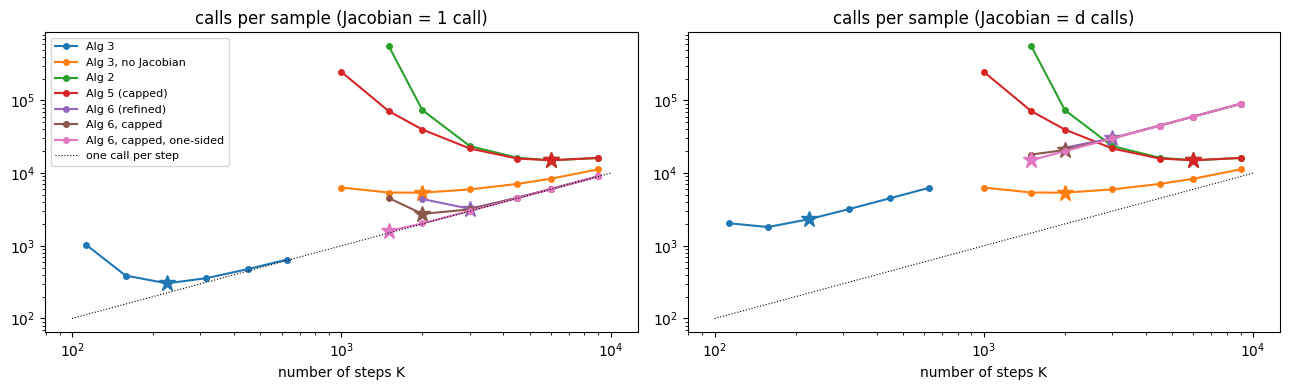

In [7]:
K_GRID = [1000, 1500, 2000, 3000, 4500, 6000, 9000]       # equal steps (Prop 4.8), kappa_{s,t} = kappa_{1,eps} / K
K0S = [0.5, 0.7, 1.0, 1.4, 2.0, 2.8]                      # Alg 3: kappa_{s,t} = k0 max(1, snr_s)^0.2

t0 = time.time()
grids = {name: [grid(KAPPA_TOT / K_, 0) for K_ in K_GRID if KAPPA_TOT / K_ <= kmax] for name, (f, jac, kmax) in METHODS.items()}
grids['Alg 3'] = [grid(k0, 0.2) for k0 in K0S]
scan = {name: {len(s) - 1: (*cost_estimate(METHODS[name][0], s), s) for s in gs} for name, gs in grids.items()}
BEST = {name: min(c, key=lambda K_: c[K_][0]) for name, c in scan.items()}
print(f'{time.time() - t0:.0f}s\n')

for name, c in scan.items():
    jac = METHODS[name][1]
    for K_, (calls_, props_, _) in c.items():
        print(f'{name:26s} K = {K_:5d}:  calls {calls_:7.0f}' + (f'  ({calls_ + (d - 1) * K_:6.0f} with the Jacobian as d calls)' if jac else ' ' * 41)
              + f'   proposals {props_:8.0f}' + ('   *' if K_ == BEST[name] else ''))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, c in scan.items():
    Ks = np.array(list(c)); cs = np.array([v[0] for v in c.values()])
    for a, extra in zip(ax, (0, (d - 1) * METHODS[name][1])):
        l, = a.plot(Ks, cs + extra * Ks, 'o-', ms=4, label=name)
        a.plot(BEST[name], c[BEST[name]][0] + extra * BEST[name], '*', c=l.get_color(), ms=12)
for a, title in zip(ax, ['calls per sample (Jacobian = 1 call)', 'calls per sample (Jacobian = d calls)']):
    a.plot([100, 10000], [100, 10000], 'k:', lw=0.8, label='one call per step')
    a.set_xscale('log'); a.set_yscale('log'); a.set_xlabel('number of steps K'); a.set_title(title)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## Runs

Each method at its cheapest $K$, $n = 1000$ trajectories from exact draws of $X_1$.

In [8]:
n = 1000
rad = lambda Y: np.linalg.norm(Y[:, :k], axis=1)          # |y_{1:k}|
rest = lambda Y: np.linalg.norm(Y[:, k:], axis=1)         # |y_{k+1:d}|
truth = sample_level(200_000, Level(EPS), np.random.default_rng(1))       # exact law of Y_{1-eps}

res = {}
for name, (f, jac, kmax) in METHODS.items():
    K_ = BEST[name]
    t0 = time.time()
    res[name] = run(f, scan[name][K_][2], n)
    calls = res[name][2]
    print(f'{name:26s} K = {K_:5d}:  calls per sample {calls.mean():6.0f} ± {calls.std():4.0f}'
          + (f'  ({calls.mean() + (d - 1) * K_:6.0f} with the Jacobian as d calls)' if jac else ' ' * 41)
          + f'   proposals {res[name][3].mean():8.0f}   {time.time() - t0:4.0f}s')

Alg 3                      K =   225:  calls per sample    310 ±   41  (  2335 with the Jacobian as d calls)   proposals     2795     10s


Alg 3, no Jacobian         K =  2000:  calls per sample   5284 ± 3141                                            proposals    24278     92s


Alg 2                      K =  6000:  calls per sample  15077 ±  177                                            proposals    15069     67s


Alg 5 (capped)             K =  6000:  calls per sample  15061 ±  175                                            proposals    15053     71s


Alg 6 (refined)            K =  3000:  calls per sample   3168 ±   42  ( 30168 with the Jacobian as d calls)   proposals     4128     36s


Alg 6, capped              K =  2000:  calls per sample   2679 ±  174  ( 20679 with the Jacobian as d calls)   proposals     9015     51s


Alg 6, capped, one-sided   K =  1500:  calls per sample   1574 ±   26  ( 15074 with the Jacobian as d calls)   proposals    34591    106s


## Samples

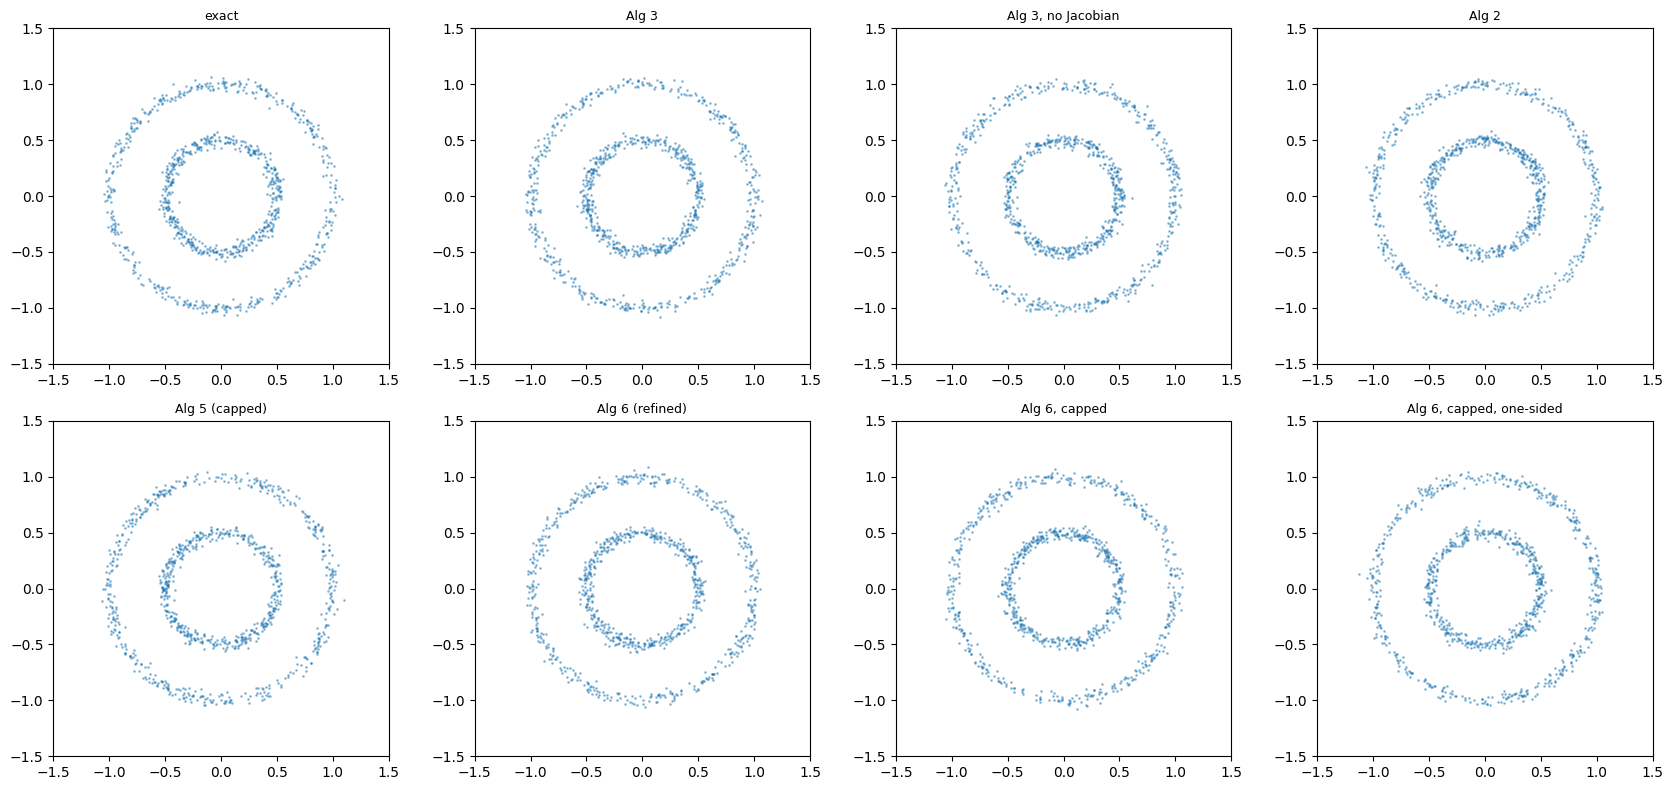

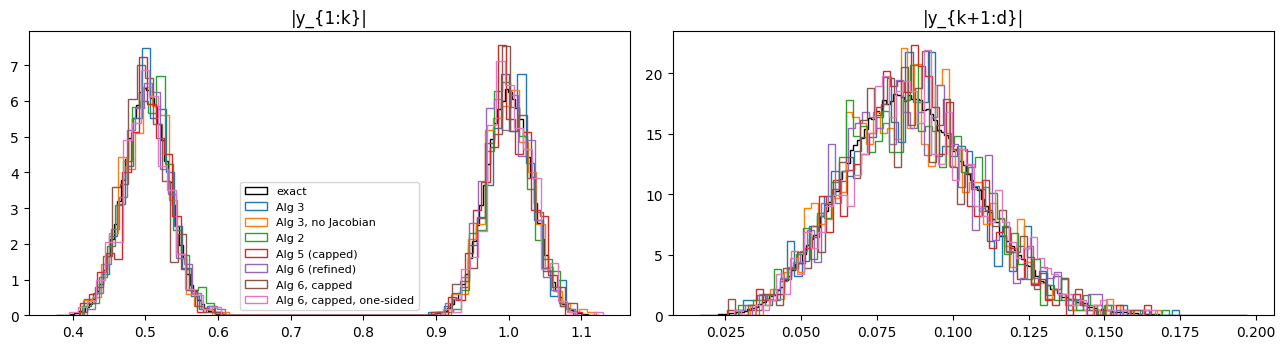

Alg 3                      KS p-values against the exact law:  |y_1:k| 0.898   |y_k+1:d| 0.950   y_1 0.522
Alg 3, no Jacobian         KS p-values against the exact law:  |y_1:k| 0.843   |y_k+1:d| 0.850   y_1 0.007
Alg 2                      KS p-values against the exact law:  |y_1:k| 0.958   |y_k+1:d| 0.226   y_1 0.715
Alg 5 (capped)             KS p-values against the exact law:  |y_1:k| 0.477   |y_k+1:d| 0.234   y_1 0.003


Alg 6 (refined)            KS p-values against the exact law:  |y_1:k| 0.691   |y_k+1:d| 0.460   y_1 0.341
Alg 6, capped              KS p-values against the exact law:  |y_1:k| 0.151   |y_k+1:d| 0.993   y_1 0.701
Alg 6, capped, one-sided   KS p-values against the exact law:  |y_1:k| 0.235   |y_k+1:d| 0.063   y_1 0.002


In [9]:
sets = {'exact': truth[:n], **{name: r[0] for name, r in res.items()}}
fig, ax = plt.subplots(2, 4, figsize=(17, 8))
for a, (name, Z) in zip(ax.flat, sets.items()):
    a.scatter(Z[:, 0], Z[:, 1], s=1, alpha=0.4)
    a.set_title(name, fontsize=9); a.set_aspect('equal'); a.set_xlim(-1.5, 1.5); a.set_ylim(-1.5, 1.5)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
for a, f, lab in [(ax[0], rad, '|y_{1:k}|'), (ax[1], rest, '|y_{k+1:d}|')]:
    a.hist(f(truth), bins=150, histtype='step', density=True, color='k', label='exact')
    for name, r in res.items():
        a.hist(f(r[0]), bins=60, histtype='step', density=True, label=name)
    a.set_title(lab)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

for name, r in res.items():
    p = [stats.ks_2samp(f(r[0]), f(truth)).pvalue for f in (rad, rest, lambda Y: Y[:, 0])]
    print(f'{name:26s} KS p-values against the exact law:  |y_1:k| {p[0]:.3f}   |y_k+1:d| {p[1]:.3f}   y_1 {p[2]:.3f}')

## Cost per step

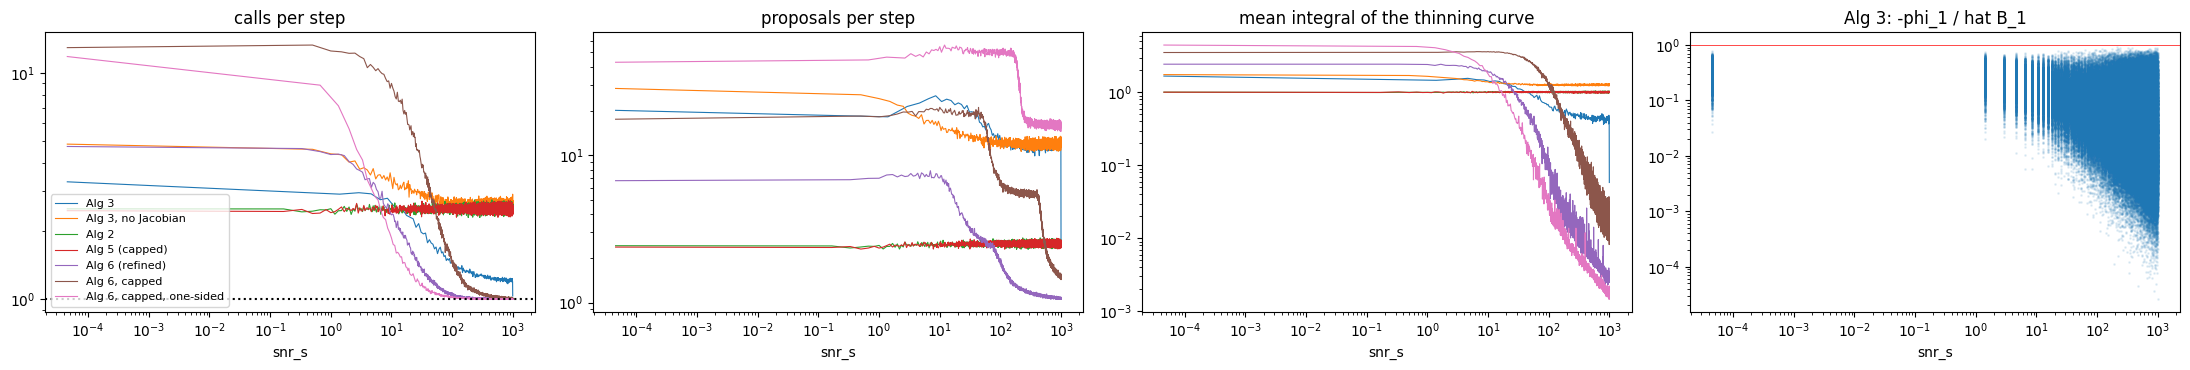

In [10]:
fig, ax = plt.subplots(1, 4, figsize=(22, 3.8))
for name, (Y, logs, calls, props) in res.items():
    snr = np.array([l['snr'] for l in logs])
    ax[0].plot(snr, [l['calls'] for l in logs], lw=0.8, label=name)
    ax[1].plot(snr, [l['props'] for l in logs], lw=0.8)
    ax[2].plot(snr, [l['area'] for l in logs], lw=0.8)
logs = res['Alg 3'][1]
ax[3].scatter(np.concatenate([np.full(l['ratio'].size, l['snr']) for l in logs]), np.concatenate([l['ratio'] for l in logs]),
              s=1, alpha=0.1, rasterized=True)
ax[3].axhline(1, c='r', lw=0.5); ax[3].set_yscale('log')
ax[0].axhline(1, c='k', ls=':'); ax[0].legend(fontsize=8)
for a, title in zip(ax, ['calls per step', 'proposals per step', 'mean integral of the thinning curve', 'Alg 3: -phi_1 / hat B_1']):
    a.set_title(title); a.set_xscale('log'); a.set_xlabel('snr_s')
for a in ax[:3]:
    a.set_yscale('log')
plt.tight_layout(); plt.show()

## One step against the exact transition

One $y$ from the law of $X_s$, $n_1$ copies, against exact draws from $q_{1-t|1-s}(\cdot|y)$, at $\kappa_{s,t} = 0.5$ for every method and at $\kappa_{s,t} = 2$ for those that allow it.

snr_s 0.3, kappa 0.5
  Alg 3                      KS p y_1 0.103  |y_1:k| 0.042  |y_k+1:d| 0.639   calls   1.32   proposals     2.2
  Alg 3, no Jacobian         KS p y_1 0.413  |y_1:k| 0.639  |y_k+1:d| 0.484   calls   4.42   proposals    23.8


  Alg 2                      KS p y_1 0.310  |y_1:k| 0.436  |y_k+1:d| 0.842   calls  30.84   proposals    29.4
  Alg 5 (capped)             KS p y_1 0.795  |y_1:k| 0.534  |y_k+1:d| 0.586   calls  17.03   proposals    16.2


  Alg 6 (refined)            KS p y_1 0.560  |y_1:k| 0.391  |y_k+1:d| 0.745   calls  24.56   proposals    28.5
  Alg 6, capped              KS p y_1 0.919  |y_1:k| 0.310  |y_k+1:d| 0.534   calls  12.83   proposals    17.9


  Alg 6, capped, one-sided   KS p y_1 0.586  |y_1:k| 0.534  |y_k+1:d| 0.534   calls   2.81   proposals    18.3
snr_s 30, kappa 0.5
  Alg 3                      KS p y_1 0.639  |y_1:k| 0.666  |y_k+1:d| 0.172   calls   1.03   proposals     1.1
  Alg 3, no Jacobian         KS p y_1 0.692  |y_1:k| 0.534  |y_k+1:d| 0.884   calls   4.65   proposals    25.9


  Alg 2                      KS p y_1 0.948  |y_1:k| 0.612  |y_k+1:d| 0.612   calls  33.28   proposals    33.1


  Alg 5 (capped)             KS p y_1 0.560  |y_1:k| 0.902  |y_k+1:d| 0.000   calls  18.39   proposals    18.3


... (6 outputs left out)

  Alg 5 (capped)             KS p y_1 0.692  |y_1:k| 0.274  |y_k+1:d| 0.935   calls 5411.78   proposals  4966.5
snr_s 30, kappa 2
  Alg 3                      KS p y_1 0.884  |y_1:k| 0.795  |y_k+1:d| 0.095   calls   1.81   proposals    10.1


  Alg 3, no Jacobian         KS p y_1 0.863  |y_1:k| 0.509  |y_k+1:d| 0.185   calls  20.92   proposals   411.3


  Alg 5 (capped)             KS p y_1 0.795  |y_1:k| 0.745  |y_k+1:d| 0.484   calls 13893.99   proposals 13431.1
snr_s 3000, kappa 2
  Alg 3                      KS p y_1 0.745  |y_1:k| 0.745  |y_k+1:d| 0.045   calls   1.00   proposals     1.0
  Alg 3, no Jacobian         KS p y_1 0.990  |y_1:k| 0.902  |y_k+1:d| 0.274   calls   1.02   proposals     1.3


  Alg 5 (capped)             KS p y_1 0.719  |y_1:k| 0.692  |y_k+1:d| 0.241   calls 25900.95   proposals 25899.5


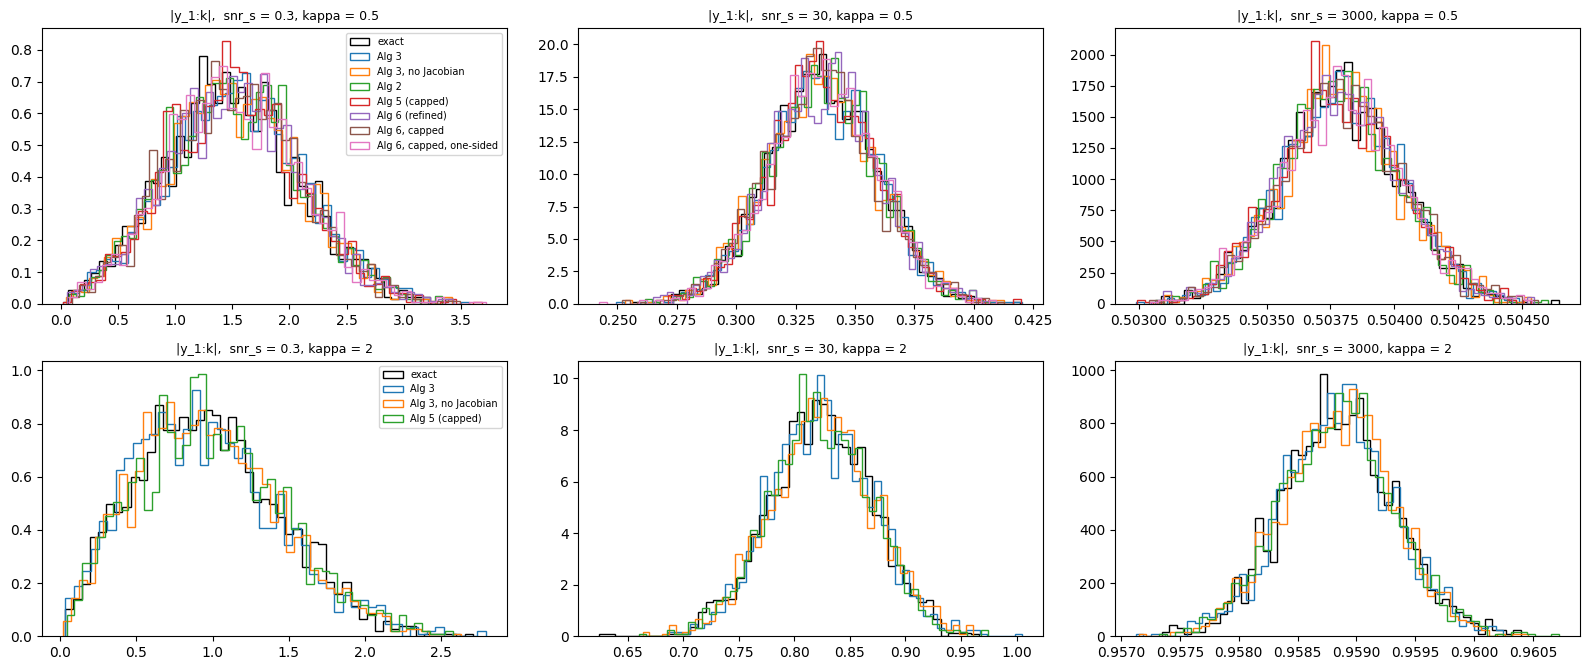

In [11]:
n1 = 2000
rng = np.random.default_rng(2)
fs ={'y_1': lambda Z: Z[:, 0], '|y_1:k|': rad, '|y_k+1:d|': rest}
KAPS = [0.5, 2.0]

fig, ax = plt.subplots(len(KAPS), 3, figsize=(16, 3.4 * len(KAPS)))
for row, kap in zip(ax, KAPS):
    for a, snr_s in zip(row, (0.3, 30, 3000)):
        S, T = level_from_snr(snr_s), level_from_snr(snr_s + kap)
        y = sample_level(1, S, rng)[0]
        Ye = exact_step(y, S, T, n1, rng)
        a.hist(rad(Ye), bins=50, histtype='step', density=True, color='k', label='exact')
        print(f'snr_s {snr_s:g}, kappa {kap:g}')
        for name, (f, jac, kmax) in METHODS.items():
            if kap > kmax:
                continue
            Ya, lg = f(np.tile(y, (n1, 1)), S, T, rng)
            p = {key: stats.ks_2samp(g(Ya), g(Ye)).pvalue for key, g in fs.items()}
            print(f'  {name:26s} KS p ' + '  '.join(f'{key} {v:.3f}' for key, v in p.items())
                  + f'   calls {lg["calls"].mean():6.2f}   proposals {lg["props"].mean():7.1f}')
            a.hist(rad(Ya), bins=50, histtype='step', density=True, label=name)
        a.set_title(f'|y_1:k|,  snr_s = {snr_s:g}, kappa = {kap:g}', fontsize=9)
    row[0].legend(fontsize=7)
plt.tight_layout(); plt.show()